<a href="https://colab.research.google.com/github/EduardoHFG/EduardoHFG/blob/main/DESAFIO_07_52624378.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Curso Ciência da Computação

**Disciplina:** Laboratório de Programação de Computadores (2ª)<br>
**Turma** N13202A · 2S.2026 | **Data:** 19.11.2026<br>
**Prof.** Álan Gonçalves<br>

---

## Desafio 06- Panorama da Atenção à Saúde no Brasil
### Dados sintéticos, conferência do arquivo e Análise Exploratória (EDA) com Pandas

## Identificação

| Nome completo | RA |
|---|---|
| *Eduardo Henrique Fitipaldi Gonsale* | *52624378* |

> Dê **dois cliques** nesta célula para editar a tabela.

### Como salvar e entregar

- O arquivo deve se chamar **`DESAFIO_07_RA.ipynb`**, trocando `RA` pelo seu número de RA. Exemplo: `DESAFIO_07_123456.ipynb`.
- **No Colab:** clique no nome do notebook (no topo da página) e renomeie. Depois, *Arquivo > Fazer download > Fazer download do .ipynb*.
- **No VS Code / Jupyter:** *File > Save As* (ou renomeie o arquivo na pasta) com o nome acima.
- Antes de baixar, use *Reiniciar e executar tudo* para que as saídas fiquem salvas no notebook.

## O cenário

Você acaba de entrar como estagiário(a) de dados no **Observatório Saúde em Números**, uma organização que acompanha indicadores de atendimento à população adulta e produz relatórios para secretarias municipais e estaduais de saúde.

O coordenador de pesquisa te chama logo no primeiro dia: *"Dados de saúde são dados pessoais sensíveis pela LGPD, e o acesso aos prontuários reais ainda vai demorar alguns meses para ser aprovado. Mas eu não quero esperar para montar o nosso fluxo de análise. Vamos gerar uma base **sintética**, com as mesmas colunas e regras que esperamos encontrar nos dados reais, e testar tudo nela. Quando os dados oficiais chegarem, é só trocar o arquivo."*

Ele termina com um alerta: *"Só tem um detalhe: base sintética não é base confiável por definição. O gerador pode ter falhado em seguir as regras, e eu quero saber exatamente onde. Confira tudo antes de tirar qualquer conclusão."*

Sua missão é transformar o pedido dele em um **prompt** para uma IA gerar a base, conferir se a base respeita o que foi pedido, explorá-la com Pandas e, no final, responder às perguntas do coordenador **com números e com senso crítico**.

## Instruções

- **Tempo previsto: 2h30**, em sala.
- Desafio **individual**, sem consultar colegas. Você pode consultar suas anotações e o material das aulas.
- Salve e entregue o notebook com o nome **`DESAFIO_07_RA.ipynb`** (veja a seção **Identificação**).
- Execute as células **na ordem**. Antes de entregar, use *Ambiente de execução > Reiniciar e executar tudo* (Colab) ou *Restart & Run All* (Jupyter) e confirme que nada quebra.
- As células marcadas com `pass` são suas: apague o `pass` e escreva o código. **Não apague os comentários-guia.**
- Onde aparecer **"Responda em comentário"**, escreva a resposta com `#` dentro da própria célula, em português, com suas palavras.
- Use apenas o que já vimos: Python, listas, dicionários, funções, leitura de arquivos, **Pandas** e **Matplotlib**.
- Resposta sem número quando a pergunta pede número vale pouco. Número sem interpretação também.

> **Pense antes de programar**
> Uma EDA não é "rodar `describe()` e seguir em frente". Para cada saída que aparecer na tela, pergunte: *o que isso me diz sobre os pacientes? Isso faz sentido? Isso respeita o que foi pedido no prompt?* A nota deste desafio está muito mais na **interpretação** do que no código.

## 1. Geração de Dados Sintéticos na área da Saúde

**Dados sintéticos** são dados criados artificialmente por um programa, imitando a estrutura e os padrões de dados reais, mas sem pertencer a nenhuma pessoa de verdade. Na saúde eles são ainda mais importantes, porque prontuários estão entre os dados mais sigilosos que existem. São muito usados para testar sistemas, treinar equipes e prototipar análises.

O fluxo do Observatório é:

1. O coordenador descreve o que precisa (o **briefing**, abaixo).
2. **Você** traduz o briefing em um **prompt** claro e completo (1.a).
3. Uma IA transforma o seu prompt em um **gerador** em Python (1.b).
4. **Você** confere se o arquivo gerado realmente respeita o que foi pedido (Seções 2 e 4.2).

Quem escreve um prompt vago recebe uma base vaga. Quem esquece uma regra no prompt não pode reclamar que a IA não a seguiu.

### 1.a Prompt de geração

#### O briefing do coordenador

> *"Preciso de uma base com **5.000 pacientes adultos** (18 anos ou mais) atendidos em 2026, cada paciente aparecendo uma única vez e identificado por um código no formato PAC00001. Quero saber onde o paciente foi atendido (região do país e a UF, que obviamente precisa pertencer àquela região), se a unidade é UBS, UPA, Hospital Público ou Hospital Privado, se fica na zona urbana ou rural, e qual foi o tipo de atendimento: Consulta, Urgência, Internação ou Cirurgia. Lembre que UBS e UPA não fazem internação nem cirurgia.*
>
> *Quero também o sexo, a idade e se a paciente está gestante. Gestante, só mulher, e com idade entre 18 e 50 anos.*
>
> *Do lado socioeconômico, quero a escolaridade do paciente (em anos de estudo), a renda familiar em salários mínimos e se ele tem plano de saúde. Do estilo de vida, os minutos de atividade física por semana.*
>
> *No atendimento, a equipe mede o peso (kg) e a altura (m) e calcula o IMC, que é o peso dividido pela altura ao quadrado. Quem desistiu e foi embora antes de ser atendido não tem medida nenhuma. Os demais recebem um desfecho: são encaminhados ao acompanhamento nutricional se tiverem IMC de 30 ou mais E fizerem menos de 150 minutos de atividade física por semana, que é a recomendação da OMS. Senão, recebem alta.*
>
> *E não quero uma base perfeita demais: cadastro real tem buraco. Deixe uns 2% a 3% de valores em branco na escolaridade, na renda e na atividade física. E o acesso à saúde e os indicadores dos pacientes têm que refletir as desigualdades socioeconômicas e regionais que a gente conhece no Brasil.*
>
> *Ah, e o arquivo vai se chamar `saude_brasil_sintetico.csv`, separado por ponto e vírgula, em UTF-8, com cabeçalho e ponto decimal. E use semente fixa 2026, para eu conseguir gerar a mesma base de novo."*

#### Dicionário de dados (nomes obrigatórios, nesta ordem)

| Coluna | Conteúdo |
|---|---|
| `id_paciente` | código único do paciente (PAC00001) |
| `data_atendimento` | data do atendimento (AAAA-MM-DD) |
| `regiao` | Norte, Nordeste, Centro-Oeste, Sudeste ou Sul |
| `uf` | sigla da UF |
| `tipo_unidade` | UBS, UPA, Hospital Público ou Hospital Privado |
| `zona` | Urbana ou Rural |
| `tipo_atendimento` | Consulta, Urgência, Internação ou Cirurgia |
| `idade` | idade em anos |
| `sexo` | F ou M |
| `gestante` | Sim ou Não |
| `escolaridade_anos` | anos de estudo do paciente (0 a 20) |
| `renda_familiar_sm` | renda familiar em salários mínimos |
| `possui_plano_saude` | Sim ou Não |
| `atividade_fisica_min_semana` | minutos de atividade física por semana |
| `peso_kg` | peso em quilogramas |
| `altura_m` | altura em metros |
| `imc` | índice de massa corporal (peso / altura²) |
| `desfecho` | Alta, Encaminhado ou Desistência |

#### Sua tarefa

Complete, na célula de texto abaixo, o prompt que você vai enviar à IA. Ele organiza o briefing em **regras numeradas**, porque as Seções 2 e 4.2 vão auditar a base regra a regra. As regras mais mecânicas (**R1, R2, R8 e R10**) já estão escritas: **você escreve R3, R4, R5, R6, R7 e R9**, as que exigem interpretar o briefing.

| Regra | Assunto |
|---|---|
| R1 | Volume e identificação |
| R2 | Colunas e ordem |
| R3 | Localização (região e UF) |
| R4 | Unidade e tipo de atendimento |
| R5 | Idade, sexo e gestação |
| R6 | Medidas e IMC |
| R7 | Desfecho |
| R8 | Unidades e formatos de cada coluna |
| R9 | Realismo (ausentes e desigualdades) |
| R10 | Formato do arquivo e reprodutibilidade |

> **Pense antes de escrever:** releia o briefing e marque cada informação. Alguma ficou implícita? (ex.: o que acontece com as medidas de quem desistiu? E se a atividade física de um paciente estiver em branco, como a IA decide o desfecho dele?) Uma regra ambígua no prompt vira uma decisão aleatória da IA.

**MEU PROMPT** *(dê dois cliques nesta célula, complete as regras marcadas com "..." e copie o prompt inteiro para a IA)*

> Gere um script Python (pandas e numpy) que crie uma base **sintética** de pacientes adultos atendidos na rede de saúde brasileira em 2026, seguindo exatamente as regras abaixo.
>
> **R1. Volume e identificação:** exatamente 5.000 linhas, uma por paciente. `id_paciente` único, no formato PAC00001 a PAC05000, sem repetição.
>
> **R2. Colunas e ordem:** exatamente estas 18 colunas, nesta ordem: id_paciente, data_atendimento, regiao, uf, tipo_unidade, zona, tipo_atendimento, idade, sexo, gestante, escolaridade_anos, renda_familiar_sm, possui_plano_saude, atividade_fisica_min_semana, peso_kg, altura_m, imc, desfecho.
>
> **R3. Localização (região e UF):** ...
>
> **R4. Unidade e tipo de atendimento:** ...
>
> **R5. Idade, sexo e gestação:** ...
>
> **R6. Medidas e IMC:** ...
>
> **R7. Desfecho:** ...
>
> **R8. Unidades e formatos:** data_atendimento no formato AAAA-MM-DD, entre janeiro e junho de 2026; idade inteira (anos); sexo F ou M; gestante Sim ou Não; escolaridade_anos inteira, de 0 a 20 (anos de estudo); renda_familiar_sm em salários mínimos, positiva, 2 casas decimais; possui_plano_saude Sim ou Não; atividade_fisica_min_semana inteira, de 0 a 600; peso_kg de 35,0 a 200,0, 1 casa decimal; altura_m de 1,40 a 2,10, 2 casas decimais; imc com 1 casa decimal.
>
> **R9. Realismo (ausentes e desigualdades):** ...
>
> **R10. Formato do arquivo e reprodutibilidade:** salvar como `saude_brasil_sintetico.csv`, separador ponto e vírgula, codificação UTF-8 (sem BOM), com cabeçalho, ponto como separador decimal, sem coluna de índice. Usar semente fixa 2026 (`np.random.default_rng(2026)`) para que a base seja sempre a mesma.

### 1.b Gerador

1. Envie o seu prompt a uma IA (ChatGPT, Gemini, Copilot, Claude etc.).
2. Cole na célula abaixo o código Python que ela devolver, **sem editar nada à mão**.
3. Execute a célula e confirme que o arquivo `saude_brasil_sintetico.csv` foi criado.

Se o código der erro ou não salvar o arquivo, **não conserte manualmente**: volte à IA, explique o problema e peça uma nova versão. Registre na 1.c quantas tentativas foram necessárias.

A partir daqui, seu papel é o de quem **recebe** a base: confiar desconfiando.

In [1]:
# Ferramenta de IA usada: Claude (Anthropic)
# Cole abaixo o gerador devolvido pela IA (sem edições manuais) e execute.

import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)
N = 5000

# ---------- R3: regiões e UFs ----------
REGIOES = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sul": ["PR", "RS", "SC"],
}
PESO_UF = {  # peso aproximado pela população de cada UF
    "AC": 0.9, "AP": 0.8, "AM": 4.0, "PA": 8.1, "RO": 1.6, "RR": 0.6, "TO": 1.5,
    "AL": 3.1, "BA": 14.1, "CE": 8.8, "MA": 6.8, "PB": 4.0, "PE": 9.1, "PI": 3.3, "RN": 3.3, "SE": 2.2,
    "DF": 2.8, "GO": 7.1, "MT": 3.7, "MS": 2.8,
    "ES": 3.8, "MG": 20.5, "RJ": 16.1, "SP": 44.4,
    "PR": 11.4, "RS": 10.9, "SC": 7.6,
}
lista_regioes = list(REGIOES.keys())
prob_regiao = np.array([sum(PESO_UF[u] for u in REGIOES[r]) for r in lista_regioes])
prob_regiao = prob_regiao / prob_regiao.sum()

regiao = rng.choice(lista_regioes, size=N, p=prob_regiao)
uf = []
for r in regiao:
    ufs = REGIOES[r]
    p = np.array([PESO_UF[u] for u in ufs])
    uf.append(rng.choice(ufs, p=p / p.sum()))
uf = np.array(uf)

# Índice de vantagem socioeconômica da região (Sul/Sudeste maior, Norte/Nordeste menor)
VANT_REGIAO = {"Norte": -1.0, "Nordeste": -1.2, "Centro-Oeste": 0.2, "Sudeste": 0.8, "Sul": 0.7}
vant = np.array([VANT_REGIAO[r] for r in regiao])

# Zona: mais rural no Norte/Nordeste
PROB_RURAL = {"Norte": 0.25, "Nordeste": 0.27, "Centro-Oeste": 0.10, "Sudeste": 0.07, "Sul": 0.14}
rural = rng.random(N) < np.array([PROB_RURAL[r] for r in regiao])
zona = np.where(rural, "Rural", "Urbana")

# ---------- Data ----------
inicio = np.datetime64("2026-01-01")
dias = rng.integers(0, 181, size=N)  # 01/01 a 30/06/2026
data_atendimento = (inicio + dias).astype(str)

# ---------- R5: idade, sexo, gestação ----------
idade = np.clip(np.round(rng.normal(46, 17, size=N)), 18, 95).astype(int)
sexo = np.where(rng.random(N) < 0.54, "F", "M")
pode_gestar = (sexo == "F") & (idade >= 18) & (idade <= 50)
gestante = np.where(pode_gestar & (rng.random(N) < 0.08), "Sim", "Não")

# ---------- Socioeconômico ----------
esc_media = 10 + 1.5 * vant - 2.5 * rural - 0.06 * (idade - 45)
escolaridade = np.clip(np.round(rng.normal(esc_media, 3.5)), 0, 20).astype(int)

log_renda = np.log(1.0) + 0.11 * escolaridade + 0.25 * vant - 0.35 * rural + rng.normal(0, 0.55, N)
renda = np.round(np.clip(np.exp(log_renda), 0.2, None), 2)

p_plano = 1 / (1 + np.exp(-(1.1 * (renda - 4.5) / 1.5 + 0.3 * vant - 0.8 * rural)))
plano = np.where(rng.random(N) < p_plano, "Sim", "Não")

# ---------- R4: unidade e tipo de atendimento ----------
tipo_unidade = []
for i in range(N):
    if plano[i] == "Sim":
        opcoes, p = ["UBS", "UPA", "Hospital Público", "Hospital Privado"], [0.12, 0.10, 0.18, 0.60]
    elif rural[i]:
        opcoes, p = ["UBS", "UPA", "Hospital Público", "Hospital Privado"], [0.65, 0.15, 0.18, 0.02]
    else:
        opcoes, p = ["UBS", "UPA", "Hospital Público", "Hospital Privado"], [0.45, 0.27, 0.25, 0.03]
    tipo_unidade.append(rng.choice(opcoes, p=p))
tipo_unidade = np.array(tipo_unidade)

tipo_atendimento = []
for u in tipo_unidade:
    if u == "UBS":
        t = rng.choice(["Consulta", "Urgência"], p=[0.90, 0.10])
    elif u == "UPA":
        t = rng.choice(["Consulta", "Urgência"], p=[0.20, 0.80])
    else:
        t = rng.choice(["Consulta", "Urgência", "Internação", "Cirurgia"], p=[0.30, 0.30, 0.25, 0.15])
    tipo_atendimento.append(t)
tipo_atendimento = np.array(tipo_atendimento)

# ---------- Atividade física ----------
p_sedentario = np.clip(0.45 - 0.015 * escolaridade - 0.03 * np.log(renda + 0.1) + 0.004 * (idade - 45), 0.05, 0.9)
sedentario = rng.random(N) < p_sedentario
minutos = rng.gamma(2.0, 40 + 5 * escolaridade + 8 * np.log(renda + 1))
atividade = np.where(sedentario, 0, np.clip(np.round(minutos), 0, 600)).astype(int)

# ---------- R6: medidas e IMC ----------
altura = np.where(sexo == "M", rng.normal(1.73, 0.07, N), rng.normal(1.61, 0.065, N))
altura = np.round(np.clip(altura, 1.40, 2.10), 2)

imc_alvo = (27.0 + 0.04 * (idade - 45) - 0.012 * (atividade - 120)
            - 0.15 * (escolaridade - 10) + 0.4 * rural + rng.normal(0, 4.5, N))
peso = np.round(np.clip(imc_alvo * altura ** 2, 35.0, 200.0), 1)
imc = np.round(peso / altura ** 2, 1)

# ---------- R7: desfecho ----------
p_desist = 0.04 + 0.05 * (tipo_unidade == "UPA") + 0.03 * rural + 0.02 * (vant < 0)
p_desist = np.where(np.isin(tipo_atendimento, ["Internação", "Cirurgia"]), 0, p_desist)
desistiu = rng.random(N) < p_desist

desfecho = np.where((imc >= 30) & (atividade < 150), "Encaminhado", "Alta")
desfecho = np.where(desistiu, "Desistência", desfecho)

peso = np.where(desistiu, np.nan, peso)
altura = np.where(desistiu, np.nan, altura)
imc = np.where(desistiu, np.nan, imc)

# ---------- Monta o DataFrame ----------
df = pd.DataFrame({
    "id_paciente": [f"PAC{i:05d}" for i in range(1, N + 1)],
    "data_atendimento": data_atendimento,
    "regiao": regiao,
    "uf": uf,
    "tipo_unidade": tipo_unidade,
    "zona": zona,
    "tipo_atendimento": tipo_atendimento,
    "idade": idade,
    "sexo": sexo,
    "gestante": gestante,
    "escolaridade_anos": escolaridade,
    "renda_familiar_sm": renda,
    "possui_plano_saude": plano,
    "atividade_fisica_min_semana": atividade,
    "peso_kg": peso,
    "altura_m": altura,
    "imc": imc,
    "desfecho": desfecho,
})

# ---------- R9: valores ausentes (depois do desfecho já calculado) ----------
for col in ["escolaridade_anos", "renda_familiar_sm", "atividade_fisica_min_semana"]:
    taxa = rng.uniform(0.02, 0.03)
    faltando = rng.random(N) < taxa
    df.loc[faltando, col] = np.nan

df["escolaridade_anos"] = df["escolaridade_anos"].astype("Int64")
df["atividade_fisica_min_semana"] = df["atividade_fisica_min_semana"].astype("Int64")

# ---------- R10: salvar ----------
df.to_csv("saude_brasil_sintetico.csv", sep=";", encoding="utf-8", index=False, decimal=".")
print("Arquivo saude_brasil_sintetico.csv criado com", df.shape[0], "linhas e", df.shape[1], "colunas.")

Arquivo saude_brasil_sintetico.csv criado com 5000 linhas e 18 colunas.


### 1.c Reflexão rápida

Responda em comentário na célula abaixo:

1. Quantas tentativas foram necessárias até o gerador funcionar? O que você precisou pedir de novo à IA?
2. Lendo o código gerado (sem precisar entender todas as linhas), você encontrou alguma regra do seu prompt que a IA **ignorou** ou interpretou de outro jeito?

In [2]:
#1. Foi apenas uma tentativa. O Claude fez o código de primeira e criou o arquivo: (saude_brasil_sintetico.csv) com 5.000 linhas e 18 colunas, sem precisar de correções. Acredito que o prompt bem organizado e com regras claras ajudou bastante.

#2. Analisando o código, percebi alguns pontos de atenção:

#O peso foi limitado entre 35 e 200 kg, o que pode gerar valores repetidos e IMCs fora da realidade.

#Os dados ausentes foram sorteados aleatoriamente, então a porcentagem final pode passar um pouco dos 3%.

#A IA tomou algumas decisões sozinha, como definir que 37% dos pacientes têm plano de saúde, acima da média brasileira.

#no geral, ela seguiu corretamente as regras do prompt, incluindo região, UF, tipos de atendimento, gestantes e cálculo dos desfechos.

## 2. Conferência do Arquivo Criado

Antes de abrir a base no Pandas, confira o **arquivo bruto**, como faria com qualquer arquivo recebido de terceiros. Nesta seção, **não use Pandas**: use `open()` e leia o conteúdo (com `split(";")` ou com o módulo `csv`).

In [3]:
# 1) Verificar o Arquivo com Open
ARQUIVO = "saude_brasil_sintetico.csv"

with open(ARQUIVO, "r", encoding="utf-8") as arquivo:
    linhas = arquivo.read().splitlines()

# Primeiras linhas do arquivo bruto
print("Primeiras 3 linhas do arquivo:")
for linha in linhas[:3]:
    print(linha)

# Cabeçalho separado em colunas
cabecalho = linhas[0].split(";")
print(f"\nColunas ({len(cabecalho)}): {cabecalho}")

# Total de registros (sem o cabeçalho)
registros = linhas[1:]
print(f"Total de registros: {len(registros)}")

Primeiras 3 linhas do arquivo:
id_paciente;data_atendimento;regiao;uf;tipo_unidade;zona;tipo_atendimento;idade;sexo;gestante;escolaridade_anos;renda_familiar_sm;possui_plano_saude;atividade_fisica_min_semana;peso_kg;altura_m;imc;desfecho
PAC00001;2026-06-14;Nordeste;PI;UBS;Urbana;Urgência;56;M;Não;6;0.59;Não;157;58.6;1.66;21.3;Alta
PAC00002;2026-01-11;Sudeste;SP;Hospital Público;Urbana;Internação;53;M;Não;13;5.48;Sim;284;54.9;1.59;21.7;Alta

Colunas (18): ['id_paciente', 'data_atendimento', 'regiao', 'uf', 'tipo_unidade', 'zona', 'tipo_atendimento', 'idade', 'sexo', 'gestante', 'escolaridade_anos', 'renda_familiar_sm', 'possui_plano_saude', 'atividade_fisica_min_semana', 'peso_kg', 'altura_m', 'imc', 'desfecho']
Total de registros: 5000


### 2.a Validar três regras do prompt

Para cada regra abaixo, escreva o código que verifica a regra e imprima uma mensagem clara de **OK** ou **FALHOU**, mostrando os números que justificam sua conclusão.

#### 2.a.1 Regra R2 - O cabeçalho tem as colunas pedidas?

In [4]:
ARQUIVO = "saude_brasil_sintetico.csv"

with open(ARQUIVO, "r", encoding="utf-8") as arquivo:
    linhas = arquivo.read().splitlines()
print("Primeiras 3 linhas do arquivo:")
for linha in linhas[:3]:
    print(linha)
cabecalho = linhas[0].split(";")
print(f"\nColunas ({len(cabecalho)}): {cabecalho}")
registros = linhas[1:]
print(f"Total de registros: {len(registros)}")

Primeiras 3 linhas do arquivo:
id_paciente;data_atendimento;regiao;uf;tipo_unidade;zona;tipo_atendimento;idade;sexo;gestante;escolaridade_anos;renda_familiar_sm;possui_plano_saude;atividade_fisica_min_semana;peso_kg;altura_m;imc;desfecho
PAC00001;2026-06-14;Nordeste;PI;UBS;Urbana;Urgência;56;M;Não;6;0.59;Não;157;58.6;1.66;21.3;Alta
PAC00002;2026-01-11;Sudeste;SP;Hospital Público;Urbana;Internação;53;M;Não;13;5.48;Sim;284;54.9;1.59;21.7;Alta

Colunas (18): ['id_paciente', 'data_atendimento', 'regiao', 'uf', 'tipo_unidade', 'zona', 'tipo_atendimento', 'idade', 'sexo', 'gestante', 'escolaridade_anos', 'renda_familiar_sm', 'possui_plano_saude', 'atividade_fisica_min_semana', 'peso_kg', 'altura_m', 'imc', 'desfecho']
Total de registros: 5000


#### 2.a.2 Regra R1 - O arquivo tem exatamente 5.000 pacientes?

In [5]:
total_linhas = len(registros)
print("Linhas de dados:", total_linhas)
ids = [linha.split(";")[0] for linha in registros]
ids_unicos = set(ids)
print("IDs únicos:", len(ids_unicos))
fora_formato = []
for i in ids:
    if not (len(i) == 8 and i[:3] == "PAC" and i[3:].isdigit()):
        fora_formato.append(i)
print("IDs fora do formato PACxx:", len(fora_formato))
if total_linhas == 5000 and len(ids_unicos) == 5000 and len(fora_formato) == 0:
    print("R1 OK: 5000 pacientes, cada um aparece uma vez e todos no formato certo.")
else:
    print("R1 FALHOU")

Linhas de dados: 5000
IDs únicos: 5000
IDs fora do formato PACxx: 0
R1 OK: 5000 pacientes, cada um aparece uma vez e todos no formato certo.


#### 2.a.3 Regra R3 - A coluna `regiao` só contém as cinco regiões oficiais?

In [6]:
pos_regiao = cabecalho.index("regiao")
pos_uf = cabecalho.index("uf")
print("Índice da coluna regiao:", pos_regiao, "| índice da coluna uf:", pos_uf)
regioes_oficiais = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
contagem = {}
invalidas = 0
for linha in registros:
    valor = linha.split(";")[pos_regiao]
    contagem[valor] = contagem.get(valor, 0) + 1
    if valor not in regioes_oficiais:
        invalidas += 1
print("Valores encontrados:", contagem)
print("Linhas com região fora das 5 oficiais:", invalidas)
if invalidas == 0:
    print("R3 (região) OK")
else:
    print("R3 (região) FALHOU")
ufs_da_regiao = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sul": ["PR", "RS", "SC"],
}
uf_errada = 0
for linha in registros:
    partes = linha.split(";")
    reg, uf_lida = partes[pos_regiao], partes[pos_uf]
    if reg not in ufs_da_regiao or uf_lida not in ufs_da_regiao[reg]:
        uf_errada += 1
print("Linhas com UF que não pertence à região:", uf_errada)
print("R3 (UF x região) OK" if uf_errada == 0 else "R3 (UF x região) FALHOU")

Índice da coluna regiao: 2 | índice da coluna uf: 3
Valores encontrados: {'Nordeste': 1342, 'Sudeste': 2113, 'Centro-Oeste': 409, 'Sul': 735, 'Norte': 401}
Linhas com região fora das 5 oficiais: 0
R3 (região) OK
Linhas com UF que não pertence à região: 0
R3 (UF x região) OK


In [7]:
# Responda em comentário:
# As regras passaram? Sim, as três passaram no arquivo:
# R2: as 18 colunas estão com os nomes certos e na ordem
# R1: 5000 linhas de dados, 5000 IDs únicos e 0 IDs fora do formato PACxx
# R3: 0 linhas com região fora das 5 oficiais (Sudeste 2113, Nordeste 1342, Sul 735,
# Centro-Oeste 409, Norte 401)
# A distribuição também faz sentido com a população: Sudeste tem bem mais q o resto

## 3. Carregamento do Dataset

Agora sim, carregue o arquivo em um DataFrame chamado `df`. Releia a regra **R10** do prompt: ela diz tudo de que você precisa para o `read_csv` funcionar corretamente.

Depois de carregar, mostre a **dimensão** da base e as **5 primeiras linhas**.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(ARQUIVO, sep=";", encoding="utf-8", decimal=".")
print("Formato:", df.shape)
df.head()

Formato: (5000, 18)


,id_paciente,data_atendimento,regiao,uf,tipo_unidade,zona,tipo_atendimento,idade,sexo,gestante,escolaridade_anos,renda_familiar_sm,possui_plano_saude,atividade_fisica_min_semana,peso_kg,altura_m,imc,desfecho
0,PAC00001,2026-06-14,Nordeste,PI,UBS,Urbana,Urgência,56,M,Não,6.0,0.59,Não,157.0,58.6,1.66,21.3,Alta
1,PAC00002,2026-01-11,Sudeste,SP,Hospital Público,Urbana,Internação,53,M,Não,13.0,5.48,Sim,284.0,54.9,1.59,21.7,Alta
2,PAC00003,2026-05-04,Sudeste,MG,Hospital Privado,Urbana,Internação,46,F,Não,17.0,12.27,Sim,NaN,48.3,1.65,17.7,Alta
3,PAC00004,2026-05-31,Centro-Oeste,MT,Hospital Público,Urbana,Consulta,65,F,Não,1.0,5.23,Sim,106.0,69.2,1.61,26.7,Alta
4,PAC00005,2026-04-20,Nordeste,CE,UPA,Rural,Consulta,43,F,Não,1.0,0.38,Não,0.0,61.8,1.47,28.6,Alta


In [9]:
# Responda em comentário:
# O número de linhas do DataFrame bate com o que você contou na Seção 2.a.2?:
# Sim. O df.shape deu (5000 e 18): 5000 linhas, igual às 5000 linhas de dados contadas com
# open() na 2.a.2, e 18 colunas, igual ao cabeçalho. o read_csv com sep=";" leu
# tudo certo (se tivesse usado o separador padrão "," ia aparecer 1 coluna só).

## 4. EDA - Análise Exploratória de Dados

A EDA tem três perguntas principais: **a base está estruturada do jeito certo? (4.1)**, **a base é confiável? (4.2)** e **como os dados se distribuem? (4.3 e 4.4)**. Só depois disso faz sentido tirar conclusões (Seção 5).

### 4.1 Estrutura - O que devo validar?

#### a. Tipos de cada coluna com `info()`

In [10]:
# Apenas Puxei df.info() pois eu ja havia colocado dentro dela
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_paciente                  5000 non-null   object 
 1   data_atendimento             5000 non-null   object 
 2   regiao                       5000 non-null   object 
 3   uf                           5000 non-null   object 
 4   tipo_unidade                 5000 non-null   object 
 5   zona                         5000 non-null   object 
 6   tipo_atendimento             5000 non-null   object 
 7   idade                        5000 non-null   int64  
 8   sexo                         5000 non-null   object 
 9   gestante                     5000 non-null   object 
 10  escolaridade_anos            4875 non-null   float64
 11  renda_familiar_sm            4854 non-null   float64
 12  possui_plano_saude           5000 non-null   object 
 13  atividade_fisica_m

In [11]:
# Responda em comentário:

#1 Sim. Comparando com a R8, algumas colunas vieram com tipos diferentes do esperado: datas e categorias apareceram
# como texto, enquanto escolaridade e atividade física vieram como float em vez de inteiro. As demais colunas estão corretas
#2 Isso aconteceu porque existem valores vazios nas colunas. Como o pandas usa NaN para representar esses dados, ele transforma os números inteiros em float para conseguir armazená-los.

#### b. Convertendo os tipos de dados

Converta as colunas cujo tipo não representa bem o seu conteúdo. Para cada conversão, deixe um comentário com o **motivo**. Pense, no mínimo, em:

- a coluna de **data**;
- as colunas de **texto com poucos valores repetidos** (categorias);
- a coluna de **anos inteiros** que tem valores ausentes (pesquise o tipo `"Int64"` do Pandas, com I maiúsculo).

Ao final, rode `info()` de novo e compare o uso de memória com o anterior.

In [12]:
memoria_antes = df.memory_usage(deep=True).sum()

df["data_atendimento"] = pd.to_datetime(df["data_atendimento"], format="%Y-%m-%d")

colunas_categoria = ["regiao", "uf", "tipo_unidade", "zona", "tipo_atendimento",
                     "sexo", "gestante", "possui_plano_saude", "desfecho"]
for col in colunas_categoria:
    df[col] = df[col].astype("category")

df["escolaridade_anos"] = df["escolaridade_anos"].astype("Int64")
df["atividade_fisica_min_semana"] = df["atividade_fisica_min_semana"].astype("Int64")

df.info()

memoria_depois = df.memory_usage(deep=True).sum()
print(f"\nMemória antes:  {memoria_antes / 1024:.0f} KB")
print(f"Memória depois: {memoria_depois / 1024:.0f} KB")
print(f"Redução: {(1 - memoria_depois / memoria_antes) * 100:.1f}%")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id_paciente                  5000 non-null   object        
 1   data_atendimento             5000 non-null   datetime64[ns]
 2   regiao                       5000 non-null   category      
 3   uf                           5000 non-null   category      
 4   tipo_unidade                 5000 non-null   category      
 5   zona                         5000 non-null   category      
 6   tipo_atendimento             5000 non-null   category      
 7   idade                        5000 non-null   int64         
 8   sexo                         5000 non-null   category      
 9   gestante                     5000 non-null   category      
 10  escolaridade_anos            4875 non-null   Int64         
 11  renda_familiar_sm            4854 non-null 

### 4.2 Qualidade

#### a. Valores ausentes com `isna().sum()`

In [13]:
print("Ausentes em escolaridade_anos:", df["escolaridade_anos"].isna().sum())
print("\nAusentes por coluna:")
print(df.isna().sum())
print("\nPercentual de ausentes nas colunas da R9:")
for col in ["escolaridade_anos", "renda_familiar_sm", "atividade_fisica_min_semana"]:
    pct = df[col].isna().mean() * 100
    situacao = "OK" if 2 <= pct <= 3 else "FORA DO PEDIDO"
    print(f"  {col}: {pct:.2f}% -> {situacao}")

Ausentes em escolaridade_anos: 125

Ausentes por coluna:
id_paciente                      0
data_atendimento                 0
regiao                           0
uf                               0
tipo_unidade                     0
zona                             0
tipo_atendimento                 0
idade                            0
sexo                             0
gestante                         0
escolaridade_anos              125
renda_familiar_sm              146
possui_plano_saude               0
atividade_fisica_min_semana    153
peso_kg                        267
altura_m                       267
imc                            267
desfecho                         0
dtype: int64

Percentual de ausentes nas colunas da R9:
  escolaridade_anos: 2.50% -> OK
  renda_familiar_sm: 2.92% -> OK
  atividade_fisica_min_semana: 3.06% -> FORA DO PEDIDO


#### b. Auditoria das regras do prompt com máscaras booleanas

Uma **máscara booleana** é uma Series de `True`/`False` que marca quais linhas atendem a uma condição. Ela permite contar (`.sum()`) e ver (`df[mascara]`) as linhas problemáticas.

Escolha **duas** regras da tabela abaixo. Para cada uma, crie a máscara que identifica as linhas que **violam** a regra, conte as violações e mostre algumas delas. Preencha apenas as células das regras escolhidas e deixe as demais com `pass`.

| Regra | O que deve ser verdade |
|---|---|
| R4 | Nenhum atendimento em UBS ou UPA é do tipo Internação ou Cirurgia |
| R5 | Toda paciente gestante é do sexo F e tem entre 18 e 50 anos |
| R6 (a) | Todo peso está entre 35,0 e 200,0 kg e toda altura entre 1,40 e 2,10 m |

> **Atenção:** pacientes com Desistência têm peso, altura e IMC em branco **de propósito** (R7). Isso não é violação da regra R6 (a).

In [14]:
mascara_r4 = (df["tipo_unidade"].isin(["UBS", "UPA"])) & \
             (df["tipo_atendimento"].isin(["Internação", "Cirurgia"]))
print("Violações da R4:", mascara_r4.sum())
print(df[mascara_r4][["id_paciente", "tipo_unidade", "tipo_atendimento"]].head())
print()
print(pd.crosstab(df["tipo_unidade"], df["tipo_atendimento"]))

Violações da R4: 0
Empty DataFrame
Columns: [id_paciente, tipo_unidade, tipo_atendimento]
Index: []

tipo_atendimento  Cirurgia  Consulta  Internação  Urgência
tipo_unidade                                              
Hospital Privado       195       368         296       341
Hospital Público       191       351         270       303
UBS                      0      1603           0       171
UPA                      0       186           0       725


In [15]:
mascara_r5 = (df["gestante"] == "Sim") & ((df["sexo"] != "F") | (df["idade"] < 18) | (df["idade"] > 50))

print("Total de gestantes:", (df["gestante"] == "Sim").sum())
print("Violações da R5:", mascara_r5.sum())
print(df[mascara_r5][["id_paciente", "sexo", "idade", "gestante"]].head())
print("\nPacientes com menos de 18 anos:", (df["idade"] < 18).sum())
print("Idade das gestantes: mín", df[df["gestante"] == "Sim"]["idade"].min(),
      "| máx", df[df["gestante"] == "Sim"]["idade"].max())

Total de gestantes: 129
Violações da R5: 0
Empty DataFrame
Columns: [id_paciente, sexo, idade, gestante]
Index: []

Pacientes com menos de 18 anos: 0
Idade das gestantes: mín 18 | máx 50


In [ ]:
# Regra R6 (a) - peso entre 35,0 e 200,0 kg e altura entre 1,40 e 2,10 m
pass

#### c. Responda em comentário

Com base em tudo o que você encontrou em 4.1 e 4.2:

In [ ]:
# Responda em comentário:

# 1 não são erros. Os 267 dados vazios de peso, altura e IMC correspondem exatamente aos 267 pacientes
# que desistiram antes do atendimento. Portanto, essas medidas não foram realizadas.
# 2 As regras R4 e R5 foram cumpridas. Porém, a R9 teve uma pequena falha: a atividade física apresentou
# 3,06% de dados ausentes, passando um pouco do limite de 3%.
# 3 Eu manteria os dados vazios, sem inventar valores ou apagar linhas. Apenas sinalizaria o problema
# no relatórip e pediria um ajuste no gerador antes de usar a base oficialmente.

### 4.3 Distribuição

#### a. Resumo das colunas numéricas com `describe()`

In [16]:
# exiba o resumo estatístico das colunas numéricas de df :
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
print(df.describe().round(2))
print("\nRenda familiar (SM): média =", round(df["renda_familiar_sm"].mean(), 2),
      "| mediana =", round(df["renda_familiar_sm"].median(), 2))
print("\nPacientes com peso exatamente 35,0 kg:", (df["peso_kg"] == 35.0).sum())
print("Pacientes com IMC abaixo de 16 (magreza grave):", (df["imc"] < 16).sum())
print("Pacientes com renda exatamente 0,20 SM:", (df["renda_familiar_sm"] == 0.2).sum())
print(df.sort_values("imc")[["id_paciente", "sexo", "idade", "peso_kg", "altura_m", "imc"]].head())

# Responda em comentário:

# 1 a maioria dos dados está dentro do esperado, mas existem valores de IMC muito baixos e 20 pacientes com exatamente 35 kg.
# isso aconteceu porque o gerador limitou o peso mínimo, criando dados pouco realistas, mesmo seguindo a regra.
# 2 a renda apresenta uma grande diferença entre média (3,84 SM) e mediana (2,83 SM). Isso mostra que poucos pacientes com renda alta aumentam a média.
# por iss, a mediana representa melhor a renda da maioria, refletindo também a desigualdade social do Brasil.

                 data_atendimento    idade  escolaridade_anos  renda_familiar_sm  atividade_fisica_min_semana  peso_kg  altura_m      imc
count                        5000  5000.00             4875.0            4854.00                       4847.0  4733.00   4733.00  4733.00
mean   2026-03-30 20:19:58.080000    46.57                9.7               3.84                       145.12    74.42      1.66    26.81
min           2026-01-01 00:00:00    18.00                0.0               0.20                          0.0    35.00      1.40    10.90
25%           2026-02-15 00:00:00    35.00                7.0               1.59                          0.0    63.30      1.60    23.30
50%           2026-03-31 00:00:00    46.00               10.0               2.83                        105.0    73.70      1.66    26.90
75%           2026-05-13 00:00:00    58.00               13.0               4.94                        227.5    85.10      1.73    30.20
max           2026-06-30 00:00:00 

### 4.4 Gráfico

Crie **um gráfico** que **responda a uma pergunta** sobre a saúde na base, com título, rótulos nos eixos e uma interpretação em comentário.

Escolha o tipo de gráfico que combina com a pergunta. Algumas ideias (você pode criar a sua):

- Como o IMC se distribui em cada **tipo de unidade**? (comparar grupos)
- Qual é a **taxa de desistência** em cada **região** ou **zona**? (comparar proporções)
- Existe relação entre **minutos de atividade física** e **IMC**? (relação entre duas variáveis numéricas)

Taxa de desistência (%):
              Urbana  Rural
Norte            6.8    6.7
Nordeste         7.1    9.0
Centro-Oeste     3.0   10.3
Sudeste          4.3    4.7
Sul              3.8    7.0

Taxa geral: 5.3 %

Pacientes da zona rural por região:
regiao
Nordeste        368
Sudeste         127
Norte           105
Sul             100
Centro-Oeste     39
Name: count, dtype: int64


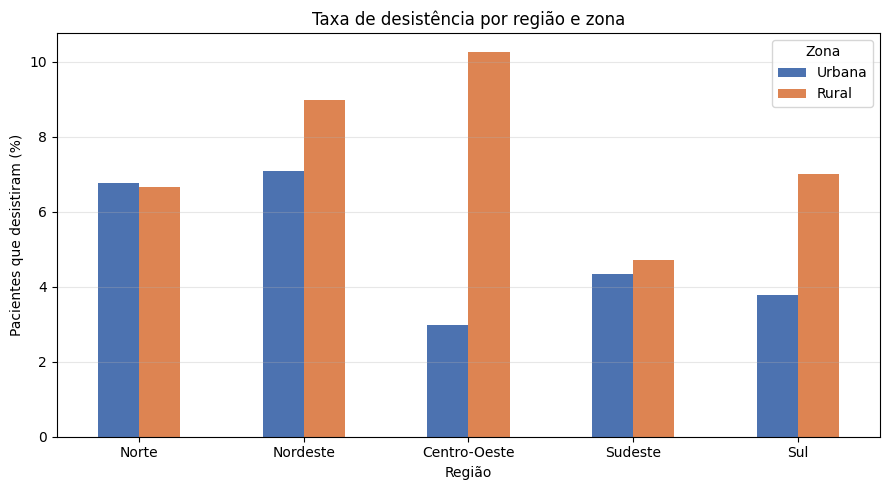

In [17]:
# gráfico
# Pergunta que este gráfico responde: a taxa de desistência (paciente que foi embora sem ser
# atendido)

regioes = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
taxa_urbana = []
taxa_rural = []
for r in regioes:
    for zona, lista in [("Urbana", taxa_urbana), ("Rural", taxa_rural)]:
        grupo = df[(df["regiao"] == r) & (df["zona"] == zona)]
        taxa = (grupo["desfecho"] == "Desistência").mean() * 100
        lista.append(taxa)

tabela = pd.DataFrame({"Urbana": taxa_urbana, "Rural": taxa_rural}, index=regioes)
print("Taxa de desistência (%):")
print(tabela.round(1))
print("\nTaxa geral:", round((df["desfecho"] == "Desistência").mean() * 100, 1), "%")
print("\nPacientes da zona rural por região:")
print(df[df["zona"] == "Rural"]["regiao"].value_counts())

tabela.plot(kind="bar", figsize=(9, 5), color=["#4C72B0", "#DD8452"])
plt.title("Taxa de desistência por região e zona")
plt.xlabel("Região")
plt.ylabel("Pacientes que desistiram (%)")
plt.xticks(rotation=0)
plt.legend(title="Zona")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#A taxa geral de desistência foi de 5,3%, sendo maior no Norte e Nordeste. No geral, a zona rural apresenta mais desistências,
# provavelmente pela distância, menor oferta de unidades e maior tempo de espera. Porém, é preciso ter cuidado com regiões que têm poucos pacientes,
# como o Centro-Oeste rural, onde pequenas mudanças podem alterar bastante a porcentagem.

## 5. EDA - Conclusões

O coordenador quer respostas objetivas para levar à reunião com a Secretaria de Saúde. Para cada pergunta: **calcule** na célula de código (usando `df`) e **responda em comentário** com os números e a sua interpretação.

#### 5.1 Plano de saúde e IMC

Pacientes com plano de saúde têm IMC médio menor do que os sem plano? Quantos pontos de diferença? **Isso prova que ter plano de saúde "causa" um IMC menor?**

Antes de responder, investigue: quem tem plano de saúde também tem renda diferente? Compare o IMC médio de quem tem e de quem não tem plano **dentro de uma mesma faixa de renda**. As faixas são uma decisão sua: defina os limites (em salários mínimos), monte uma máscara para cada faixa e justifique a escolha.

In [18]:
com_imc = df[df["imc"].notna()]

imc_com_plano = com_imc[com_imc["possui_plano_saude"] == "Sim"]["imc"].mean()
imc_sem_plano = com_imc[com_imc["possui_plano_saude"] == "Não"]["imc"].mean()
print(f"IMC médio COM plano: {imc_com_plano:.2f}")
print(f"IMC médio SEM plano: {imc_sem_plano:.2f}")
print(f"Diferença: {imc_sem_plano - imc_com_plano:.2f} pontos")

print("\nRenda familiar (SM) por plano:")
print(df.groupby("possui_plano_saude", observed=True)["renda_familiar_sm"].agg(["mean", "median"]).round(2))

# faixas de renda (decisão minha):
#baixa: até 2 SM | média: > 2 até 5 SM | alta: > de 5 SM
base = com_imc[com_imc["renda_familiar_sm"].notna()]
faixas = {
    "Baixa (até 2 SM)": base["renda_familiar_sm"] <= 2,
    "Média (2 a 5 SM)": (base["renda_familiar_sm"] > 2) & (base["renda_familiar_sm"] <= 5),
    "Alta (acima de 5 SM)": base["renda_familiar_sm"] > 5,}
print("\nIMC médio por faixa de renda e plano:")
for nome, mascara in faixas.items():
    faixa = base[mascara]
    com = faixa[faixa["possui_plano_saude"] == "Sim"]["imc"]
    sem = faixa[faixa["possui_plano_saude"] == "Não"]["imc"]
    print(f"{nome}: com plano {com.mean():.2f} (n={len(com)}) | "
          f"sem plano {sem.mean():.2f} (n={len(sem)}) | diferença {sem.mean() - com.mean():.2f}")

# Resposta (em comentário):
# sim, quem tem plano apresenta IMC medio menor (25,88 contra 27,36). Porem, isso não significa que o plano seja o responsável, já que essas pessoas também têm renda maior.
# ao comparar pessoas com rendas parecidas, a diferença de IMC cai de 1,48 para cerca de 0,4 ponto. Isso mostra que a renda influencia mais nessa relação do que ter plano de saúde.
# alem disso, os dados mostram apenas uma associação, não uma causa. Outros fatores, como escolaridade e atividade física, também podem influenciar os resultados.

IMC médio COM plano: 25.88
IMC médio SEM plano: 27.36
Diferença: 1.48 pontos

Renda familiar (SM) por plano:
                    mean  median
possui_plano_saude              
Não                 2.32    1.98
Sim                 6.51    5.60

IMC médio por faixa de renda e plano:
Baixa (até 2 SM): com plano 27.51 (n=116) | sem plano 27.96 (n=1461) | diferença 0.45
Média (2 a 5 SM): com plano 26.52 (n=609) | sem plano 26.88 (n=1273) | diferença 0.37
Alta (acima de 5 SM): com plano 25.32 (n=984) | sem plano 25.74 (n=153) | diferença 0.42


#### 5.2 O limite do sintético

Que **limitação** um dataset **sintético** traz para o que você concluiu no gráfico da 4.4 e na 5.1? Releia a regra **R9** do prompt antes de responder: de onde vieram os padrões que você "descobriu"?

In [19]:
# a principal limitação é que os padrões encontrados já foram definidos no próprio gerador. Ou seja, as análises apenas confirmam o que foi programado,
# não são descobertas sobre pacientes reais.
# além disso, os números podem mudar dependendo da simulação, e alguns dados gerados não são realistas, como pacientes com peso muito baixo.
# portanto, essa base serve para testar análises, gráficos e regras, mas não deve ser usada para tirar conclusões sobre a saúde da população. Isso só será possível quando os dados reais chegarem.

## Desafio extra (bônus - para quem terminar antes)

O coordenador gostou do trabalho e deixou mais duas perguntas. Você não precisa implementar tudo, mas explique em comentário como resolveria cada uma:

1. **Classificação do IMC:** como você criaria uma coluna `faixa_imc` com as categorias da OMS (Baixo peso, Normal, Sobrepeso e Obesidade)? Que limites usaria para cada uma? O que fazer com os pacientes que desistiram? E com as gestantes, para quem o IMC comum não se aplica bem?
2. **Troca pela base real:** quando os dados oficiais chegarem, quais partes deste notebook continuariam funcionando sem mudança e quais você teria que revisar? Por quê?

In [20]:
# Respostas do bônus (em comentário, código opcional):
# 1.
#
# 2.

## Como este desafio será avaliado

**Valor total: 1,0 ponto**

| Critério | Peso | Pontos | O que será observado |
|---|:---:|:---:|---|
| Prompt e geração (Seção 1) | 10% | 0,10 | Regras R3 a R7 e R9 escritas sem ambiguidades (ex.: medidas de quem desistiu, desfecho de quem tem atividade física em branco, regra de encaminhamento com E); gerador colado sem edição manual e executado; reflexão 1.c honesta sobre o que a IA ignorou. |
| Conferência do arquivo (Seção 2) | 10% | 0,10 | As três regras (R2, R1 e R3) verificadas lendo o arquivo bruto, sem Pandas, com mensagem OK/FALHOU e números que justificam. |
| Estrutura e tipos (4.1) | 10% | 0,10 | `info()` interpretado; conversões coerentes com a R8 e **justificadas**. |
| Qualidade e auditoria das regras (4.2) | 20% | 0,20 | Ausentes quantificados; uma máscara booleana correta para cada uma das **duas regras escolhidas**; distinção entre ausente **esperado** (Desistência) e falha real; decisão de tratamento justificada. |
| Distribuição (4.3) | 10% | 0,10 | `describe()` **lido**, não só executado, com respostas às perguntas da célula (extremos e média x mediana da renda). |
| Gráfico (4.4) | 10% | 0,10 | Gráfico adequado à pergunta escolhida (tipo coerente), com título, eixos rotulados e interpretação. |
| Conclusões (Seção 5) | 25% | 0,25 | Respostas com números calculados; distinção entre **correlação e causalidade**, com a comparação dentro de faixas de renda (5.1); reflexão crítica sobre os limites do dado sintético (5.2). |
| Organização e reprodutibilidade | 5% | 0,05 | Notebook executa do início ao fim sem erros (*Reiniciar e executar tudo*); nomes de variáveis claros; código comentado e no espírito do PEP8. |
| **Total** | **100%** | **1,00** | |

**Níveis de atendimento aplicados a cada critério**

| Nível | Fração dos pontos do critério | Descrição |
|---|:---:|---|
| Completo | 100% | Código correto **e** interpretação clara, com números e justificativa. |
| Parcial | 50% | Código correto sem interpretação, ou interpretação sem o cálculo que a sustenta. |
| Insuficiente | 0% | Célula em branco, código que não executa ou resposta sem relação com a pergunta. |

**Observações**

- Notebook que não executa do início ao fim terá desconto no critério de organização e nos critérios das células com erro.
- O bônus não soma pontos além de 1,0, mas pode compensar perdas pontuais em Conclusões.
- Cada aluno tem a **sua** base, então os números variam de entrega para entrega. A correção avalia se cálculos e respostas são **coerentes com a base gerada pelo próprio aluno**.
- Uso de IA fora da Seção 1.b ou cópia entre colegas leva à desconsideração da entrega.

---

*Boa sorte! E lembre-se: em saúde, um número mal interpretado vira política pública mal desenhada, e quem paga a conta é o paciente. Antes de concluir, desconfie, confira e só então afirme. Capriche.*